# Phase 1: Cleaning the Telco churn dataset

**The plan**
| Part | What we do |
|---|---|
| A | Load the data and take a first look |
| B | Check data quality: missing values, duplicates, wrong formats, inconsistent labels, outliers, class imbalance |
| C | Fix each problem, and say why we chose that fix |
| D | Final checks and save the clean file |

**The dataset:** IBM Telco Customer Churn (Kaggle, user *blastchar*). One row = one customer of a phone and internet company. The column **Churn** says whether the customer left (Yes) or stayed (No). That is what we will later try to predict.

---
# Part A: Load and look

## Step 1. Import the libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Step 2. Load the raw file

In [8]:
telco_df = pd.read_csv("data_raw/Telco_Customer_Churn.csv")

In [9]:
telco_df.shape

(7043, 21)

## Step 3. Look at the first rows

In [10]:
telco_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


What to notice:
- `customerID` is just a label like `7590-VHVEG`.
- Many columns hold text such as `Yes`, `No`, `No phone service`.
- `tenure` is how many months the person has been a customer.
- `MonthlyCharges` is the monthly bill; `TotalCharges` is everything they have paid so far.

## Step 4. Check the type of each column

In [13]:
telco_df.info()  

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


---
# Part B: Data quality checks

## Step 5. Missing values 


In [14]:
telco_df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## Step 6. Hidden missing values

In [20]:
blank = telco_df["TotalCharges"].str.strip() == ""
blank.sum()

np.int64(11)

**Problem found:** 11 customers have a blank `TotalCharges`.

In [22]:
telco_df.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [24]:
assert (telco_df.loc[blank, "tenure"] == 0).all()
print("Confirmed: every blank TotalCharges belongs to a customer with tenure 0")

Confirmed: every blank TotalCharges belongs to a customer with tenure 0


## Step 7. Duplication

In [27]:
print("Duplicated rows:", telco_df.duplicated().sum())
print("Repeated customer IDs:", telco_df["customerID"].duplicated().sum())

Duplicated rows: 0
Repeated customer IDs: 0


In [29]:
telco_df.drop(columns="customerID").duplicated().sum()

np.int64(22)

## Step 8. Inconsistent labels in the text columns

In [31]:
text_cols = telco_df.select_dtypes(include="object").columns.drop(["customerID", "TotalCharges"])
list(text_cols)

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'Churn']

In [33]:
for c in text_cols:
    counts = telco_df[c].value_counts()
    print(c, ":", ", ".join(f"{k} = {v}" for k, v in counts.items()))

gender : Male = 3555, Female = 3488
Partner : No = 3641, Yes = 3402
Dependents : No = 4933, Yes = 2110
PhoneService : Yes = 6361, No = 682
MultipleLines : No = 3390, Yes = 2971, No phone service = 682
InternetService : Fiber optic = 3096, DSL = 2421, No = 1526
OnlineSecurity : No = 3498, Yes = 2019, No internet service = 1526
OnlineBackup : No = 3088, Yes = 2429, No internet service = 1526
DeviceProtection : No = 3095, Yes = 2422, No internet service = 1526
TechSupport : No = 3473, Yes = 2044, No internet service = 1526
StreamingTV : No = 2810, Yes = 2707, No internet service = 1526
StreamingMovies : No = 2785, Yes = 2732, No internet service = 1526
Contract : Month-to-month = 3875, Two year = 1695, One year = 1473
PaperlessBilling : Yes = 4171, No = 2872
PaymentMethod : Electronic check = 2365, Mailed check = 1612, Bank transfer (automatic) = 1544, Credit card (automatic) = 1522
Churn : No = 5174, Yes = 1869


In [36]:
no_net = telco_df["InternetService"] == "No"
print("Customers with InternetService = No:", no_net.sum())
print("Customers with OnlineSecurity = 'No internet service':", (telco_df["OnlineSecurity"] == "No internet service").sum())
print("Same people?", (no_net == (telco_df["OnlineSecurity"] == "No internet service")).all())

Customers with InternetService = No: 1526
Customers with OnlineSecurity = 'No internet service': 1526
Same people? True


## Step 9. Outliers detection


In [37]:
num_cols = ["tenure", "MonthlyCharges"]
telco_df[num_cols].describe()

,tenure,MonthlyCharges
count,7043.000000,7043.000000
mean,32.371149,64.761692
std,24.559481,30.090047
min,0.000000,18.250000
25%,9.000000,35.500000
50%,29.000000,70.350000
75%,55.000000,89.850000
max,72.000000,118.750000


A common rule from statistics is the IQR rule: IQR = Q3 − Q1.

In [39]:
for c in num_cols:
    q1, q3 = telco_df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((telco_df[c] < low) | (telco_df[c] > high)).sum()
    print(f"{c}: allowed range {low:.1f} to {high:.1f}, outliers = {n_out}")

tenure: allowed range -60.0 to 124.0, outliers = 0
MonthlyCharges: allowed range -46.0 to 171.4, outliers = 0


A nother rule is box plot

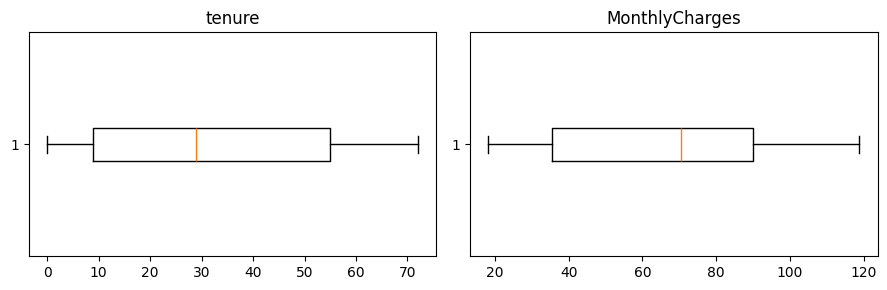

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, c in zip(axes, num_cols):
    ax.boxplot(telco_df[c], vert=False)
    ax.set_title(c)
plt.tight_layout()
plt.show()

## Step 10. Class imbalance in the target

The **target** is the column we want to predict: `Churn`. If one answer is much more common than the other, the data is **imbalanced**.

`value_counts(normalize=True)` gives proportions instead of counts.

In [42]:
print(telco_df["Churn"].value_counts())
print(telco_df["Churn"].value_counts(normalize=True).round(3))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


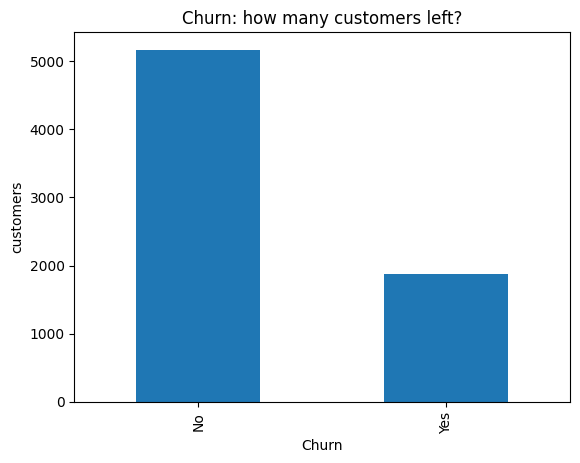

In [43]:
telco_df["Churn"].value_counts().plot(kind="bar", title="Churn: how many customers left?")
plt.ylabel("customers")
plt.show()

**Problem found:** about 73% stayed and 27% left. Why it matters: a lazy model that always says "No" would already be 73% correct, while catching zero churners. So later we must judge models with measures like recall, F1 or ROC-AUC, not just accuracy.

We do **not** fix this now. See Step 17 for why.

### Summary of what we found

| Check | Result |
|---|---|
| Format | `TotalCharges` stored as text |
| Missing | 11 hidden blanks in `TotalCharges` (all tenure = 0) |
| Duplicates | none (22 look-alike profiles, kept) |
| Labels | "No internet service" / "No phone service" repeat what other columns say |
| Outliers | none by the IQR rule |
| Imbalance | 73% No / 27% Yes |

---
# Part C: Fix each problem

From here on, every cell matches a line in `clean_data.py`. We keep the original `telco_df` untouched for comparison, and make a copy called `clean` to change.

In [44]:
clean_telco_df = telco_df.copy()

## Step 11. Fix TotalCharges: text → number, blanks → 0

`pd.to_numeric(..., errors="coerce")` turns text into numbers. *coerce* means "if you can't convert it, put NaN (missing) instead of crashing". So the 11 blanks become NaN. Then `.fillna(0.0)` replaces those NaN with 0.

**Why 0 and not the average?** Step 6 showed these customers have tenure 0, so they have truly paid nothing yet. Filling with the average (about \$2,280) would invent money they never paid. Deleting the rows would also work (only 11 of 7,043), but 0 is the *correct* value, so we keep them.

In [46]:
clean_telco_df["TotalCharges"] = pd.to_numeric(clean_telco_df["TotalCharges"], errors="coerce").fillna(0.0)
print(clean_telco_df["TotalCharges"].dtype, "| missing:", clean_telco_df["TotalCharges"].isna().sum())

float64 | missing: 0


Total paid should be roughly months × monthly bill. The correlation (a number from −1 to 1) should be close to 1.

In [47]:
approx = clean_telco_df["tenure"] * clean_telco_df["MonthlyCharges"]
print("Correlation:", round(np.corrcoef(approx, clean_telco_df["TotalCharges"])[0, 1], 3))

Correlation: 1.0


## Step 12. Drop customerID

**Why?** An ID is just a name tag. It is unique for every person, so it carries no pattern a model could learn from. Worse, a model could "memorise" IDs and look good for the wrong reason. We checked in Step 7 that it has no duplicates, so its job is done.

In [49]:
clean_telco_df = clean_telco_df.drop(columns="customerID")
clean_telco_df.shape

(7043, 20)

## Step 13. Merge "No internet service" / "No phone service" into "No"

`.replace({old: new})` swaps values. We do this for the 7 service columns.

**Why?** Step 8 showed the "no internet" information already lives in `InternetService` (and "no phone" in `PhoneService`). After the merge each of these columns becomes a simple Yes/No question: *does this customer have this service?*